# Supply Chain Late Delivery Risk Prediction

 
**By:** Olimpia Santacruz

## Business Objective

Develop a predictive model that identifies orders at risk of late delivery using only information available at the moment the order is created.

The model will support supply chain teams in prioritizing preventive actions before delivery commitments are affected.

## Decision

Which orders should the supply chain team review and prioritize because they have a high probability of being delivered late?

## Unit of Analysis

Each observation represents an order item.

## Target

`Late_delivery_risk`

- `1`: The delivery was late.
- `0`: The delivery was not late.

## Prediction Moment

The prediction will be generated when the order is created, before the shipment and final delivery outcomes are known.

## Business Success Criteria

- Identify a useful proportion of future late deliveries.
- Prioritize a manageable number of high-risk orders.
- Provide interpretable risk factors.
- Support proactive operational decisions.
- Avoid using information unavailable at the prediction moment.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Python: 3.13.15
Pandas: 3.0.5
NumPy: 2.5.3
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [2]:
# Identify the project root regardless of where the notebook starts
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

DATA_PATH = DATA_DIR / "DataCoSupplyChainDataset.csv"
DESCRIPTION_PATH = DATA_DIR / "DescriptionDataCoSupplyChain.csv"

print("Project root:", PROJECT_ROOT)
print("Data file exists:", DATA_PATH.exists())
print("Description file exists:", DESCRIPTION_PATH.exists())

Project root: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery
Data file exists: True
Description file exists: True


In [3]:
try:
    df_raw = pd.read_csv(
        DATA_PATH,
        encoding="utf-8",
        low_memory=False
    )
    encoding_used = "utf-8"

except UnicodeDecodeError:
    df_raw = pd.read_csv(
        DATA_PATH,
        encoding="latin-1",
        low_memory=False
    )
    encoding_used = "latin-1"

print("Encoding used:", encoding_used)
print("Dataset shape:", df_raw.shape)

display(df_raw.head())

Encoding used: latin-1
Dataset shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
try:
    df_description = pd.read_csv(
        DESCRIPTION_PATH,
        encoding="utf-8",
        low_memory=False
    )
    description_encoding = "utf-8"

except UnicodeDecodeError:
    df_description = pd.read_csv(
        DESCRIPTION_PATH,
        encoding="latin-1",
        low_memory=False
    )
    description_encoding = "latin-1"

print("Description encoding:", description_encoding)
print("Description shape:", df_description.shape)
print("Description columns:", df_description.columns.tolist())

display(df_description.head(10))

Description encoding: utf-8
Description shape: (52, 2)
Description columns: ['FIELDS', 'DESCRIPTION']


,FIELDS,DESCRIPTION
0,Type,: Type of transaction made
1,Days for shipping (real),: Actual shipping days of the purchased product
2,Days for shipment (scheduled),: Days of scheduled delivery of the purchased...
3,Benefit per order,: Earnings per order placed
4,Sales per customer,: Total sales per customer made per customer
5,Delivery Status,: Delivery status of orders: Advance shipping...
6,Late_delivery_risk,: Categorical variable that indicates if send...
7,Category Id,: Product category code
8,Category Name,: Description of the product category
9,Customer City,: City where the customer made the purchase


In [5]:
dataset_columns = set(df_raw.columns)

description_columns = set(
    df_description["FIELDS"]
    .astype(str)
    .str.strip()
)

missing_in_description = [
    column for column in df_raw.columns
    if column not in description_columns
]

not_in_dataset = [
    column for column in description_columns
    if column not in dataset_columns
]

duplicated_descriptions = (
    df_description.loc[
        df_description["FIELDS"].duplicated(keep=False),
        "FIELDS"
    ]
    .tolist()
)

print("Dataset columns:", len(dataset_columns))
print("Documented columns:", len(description_columns))
print("Missing in description:", missing_in_description)
print("Documented but not found in dataset:", not_in_dataset)
print("Duplicated fields in description:", duplicated_descriptions)

Dataset columns: 53
Documented columns: 52
Missing in description: ['Order Zipcode', 'shipping date (DateOrders)']
Documented but not found in dataset: ['Shipping date (DateOrders)']
Duplicated fields in description: []


## Data Dictionary Validation

The dataset contains 53 columns, while the data dictionary contains 52 documented fields.

Two inconsistencies were identified:

1. `Order Zipcode` is present in the dataset but is not documented.
2. `shipping date (DateOrders)` appears in the dictionary as `Shipping date (DateOrders)`, creating a case-sensitive name mismatch.

The original dataset and dictionary will remain unchanged. Column names will be standardized later in a separate working copy to preserve traceability.

In [6]:
audit_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=False)
})

audit_summary = audit_summary.sort_values(
    by=["missing_pct", "unique_values"],
    ascending=[False, True]
)

exact_duplicate_rows = df_raw.duplicated().sum()
memory_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
print("Exact duplicate rows:", exact_duplicate_rows)
print(f"Memory usage: {memory_mb:.2f} MB")

display(audit_summary)

Rows: 180519
Columns: 53
Exact duplicate rows: 0
Memory usage: 299.94 MB


,dtype,missing_count,missing_pct,unique_values
Product Description,float64,180519,100.00,1
Order Zipcode,float64,155679,86.24,610
Customer Email,str,0,0.00,1
Customer Password,str,0,0.00,1
Product Status,int64,0,0.00,1
Late_delivery_risk,int64,0,0.00,2
Customer Country,str,0,0.00,2
Customer Segment,str,0,0.00,3
Type,str,0,0.00,4
Days for shipment (scheduled),int64,0,0.00,4


In [7]:
missing_summary = audit_summary.loc[
    audit_summary["missing_count"] > 0,
    ["dtype", "missing_count", "missing_pct", "unique_values"]
]

print("Columns with missing values:", len(missing_summary))

display(missing_summary)

Columns with missing values: 4


,dtype,missing_count,missing_pct,unique_values
Product Description,float64,180519,100.00,1
Order Zipcode,float64,155679,86.24,610
Customer Zipcode,float64,3,0.00,996
Customer Lname,str,8,0.00,1110


## Missing-Value Assessment

Four variables contain missing values:

- `Product Description` is completely missing and provides no predictive information. It will be excluded.
- `Order Zipcode` is 86.24% missing and is largely redundant with other geographical variables. It will be excluded.
- `Customer Zipcode` contains only three missing observations, but it represents a high-cardinality geographical identifier. It will not be numerically imputed and its predictive value will be evaluated before modeling.
- `Customer Lname` contains eight missing values, but customer names are personally identifying information and should not be used as predictors. The variable will be excluded.

No rows will be removed solely because of these missing values.

In [8]:
TARGET = "Late_delivery_risk"

target_summary = (
    df_raw[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("class")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    target_summary["count"] / len(df_raw) * 100
).round(2)

print("Target:", TARGET)
print("Missing target values:", df_raw[TARGET].isna().sum())
print("Unique target values:", sorted(df_raw[TARGET].dropna().unique().tolist()))

display(target_summary)

Target: Late_delivery_risk
Missing target values: 0
Unique target values: [0, 1]


,class,count,percentage
0,0,81542,45.17
1,1,98977,54.83


## Target Assessment

The target variable is `Late_delivery_risk`.

- `1`: Late delivery.
- `0`: On-time or early delivery.
- Missing target values: 0.
- Late-delivery rate: 54.83%.
- Non-late-delivery rate: 45.17%.

The target is binary and does not present severe class imbalance. Therefore, no synthetic oversampling or automatic class balancing will be applied initially.

A naive classifier that predicts every observation as late would achieve 54.83% accuracy. Model performance must therefore be evaluated beyond accuracy, using recall, precision, PR-AUC, ROC-AUC, probability calibration and operational usefulness.

In [9]:
order_audit = (
    df_raw.groupby("Order Id")
    .agg(
        rows_per_order=("Order Id", "size"),
        target_values=("Late_delivery_risk", "nunique")
    )
)

unique_orders = df_raw["Order Id"].nunique()
orders_with_multiple_rows = (order_audit["rows_per_order"] > 1).sum()
inconsistent_target_orders = (order_audit["target_values"] > 1).sum()

print("Dataset rows:", len(df_raw))
print("Unique Order Id values:", unique_orders)
print("Orders with multiple rows:", orders_with_multiple_rows)
print("Minimum rows per order:", order_audit["rows_per_order"].min())
print("Median rows per order:", order_audit["rows_per_order"].median())
print("Maximum rows per order:", order_audit["rows_per_order"].max())
print("Orders with inconsistent target:", inconsistent_target_orders)

display(
    order_audit["rows_per_order"]
    .value_counts()
    .sort_index()
    .rename_axis("rows_per_order")
    .reset_index(name="number_of_orders")
)

Dataset rows: 180519
Unique Order Id values: 65752
Orders with multiple rows: 45902
Minimum rows per order: 1
Median rows per order: 3.0
Maximum rows per order: 5
Orders with inconsistent target: 0


,rows_per_order,number_of_orders
0,1,19850
1,2,11447
2,3,11398
3,4,11704
4,5,11353


In [10]:
order_target = (
    df_raw[["Order Id", "Late_delivery_risk"]]
    .drop_duplicates(subset="Order Id")
)

order_target_summary = (
    order_target["Late_delivery_risk"]
    .value_counts()
    .sort_index()
    .rename_axis("class")
    .reset_index(name="order_count")
)

order_target_summary["percentage"] = (
    order_target_summary["order_count"]
    / len(order_target)
    * 100
).round(2)

print("Unique orders:", len(order_target))

display(order_target_summary)

Unique orders: 65752


,class,order_count,percentage
0,0,29704,45.18
1,1,36048,54.82


In [11]:
candidate_order_level_columns = [
    "order date (DateOrders)",
    "Customer Id",
    "Customer Segment",
    "Market",
    "Order Region",
    "Order Country",
    "Shipping Mode",
    "Days for shipment (scheduled)"
]

consistency_results = []

for column in candidate_order_level_columns:
    unique_values_per_order = (
        df_raw.groupby("Order Id")[column]
        .nunique(dropna=False)
    )

    consistency_results.append({
        "column": column,
        "inconsistent_orders": (unique_values_per_order > 1).sum(),
        "maximum_values_within_one_order": unique_values_per_order.max()
    })

order_level_consistency = pd.DataFrame(consistency_results)

display(order_level_consistency)

,column,inconsistent_orders,maximum_values_within_one_order
0,order date (DateOrders),0,1
1,Customer Id,0,1
2,Customer Segment,0,1
3,Market,0,1
4,Order Region,0,1
5,Order Country,0,1
6,Shipping Mode,0,1
7,Days for shipment (scheduled),0,1


In [12]:
candidate_item_level_columns = [
    "Category Id",
    "Category Name",
    "Product Card Id",
    "Product Name",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Sales",
    "Order Item Total",
    "Order Item Profit Ratio",
    "Order Profit Per Order"
]

item_consistency_results = []

for column in candidate_item_level_columns:
    unique_values_per_order = (
        df_raw.groupby("Order Id")[column]
        .nunique(dropna=False)
    )

    item_consistency_results.append({
        "column": column,
        "inconsistent_orders": (unique_values_per_order > 1).sum(),
        "maximum_values_within_one_order": unique_values_per_order.max()
    })

item_level_consistency = pd.DataFrame(item_consistency_results)

display(item_level_consistency)

,column,inconsistent_orders,maximum_values_within_one_order
0,Category Id,44563,5
1,Category Name,44563,5
2,Product Card Id,44578,5
3,Product Name,44578,5
4,Order Item Quantity,38816,5
5,Order Item Product Price,44557,5
6,Order Item Discount,45780,5
7,Order Item Discount Rate,45269,5
8,Sales,45190,5
9,Order Item Total,45902,5


## Data Granularity and Prediction Unit

The raw dataset is recorded at the order-item level. It contains 180,519 rows corresponding to 65,752 unique orders.

Each order may contain between one and five item rows. The late-delivery target is consistent across all items belonging to the same order, indicating that the delivery outcome is defined at the order level.

Therefore:

- **Raw-data unit:** One order item.
- **Prediction unit:** One complete order.
- **Target unit:** One complete order.

Order-level variables will retain one value per `Order Id`. Item-level variables will be aggregated using operationally meaningful features such as:

- Total item quantity.
- Total order value.
- Number of distinct products.
- Number of distinct categories.
- Total discount.
- Profit-related summaries.

Only information available when the order is created will be included. This prevents multi-item orders from receiving disproportionate weight and ensures that each order receives one risk prediction.

In [13]:
calculated_late_risk = (
    df_raw["Days for shipping (real)"]
    > df_raw["Days for shipment (scheduled)"]
).astype(int)

target_agreement = (
    calculated_late_risk == df_raw["Late_delivery_risk"]
).mean()

mismatched_rows = (
    calculated_late_risk != df_raw["Late_delivery_risk"]
).sum()

print(f"Agreement with calculated target: {target_agreement:.4%}")
print("Mismatched rows:", mismatched_rows)

display(
    pd.crosstab(
        df_raw["Delivery Status"],
        df_raw["Late_delivery_risk"],
        margins=True
    )
)

Agreement with calculated target: 97.5498%
Mismatched rows: 4423


Late_delivery_risk,0,1,All
Delivery Status,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519


In [14]:
target_comparison = pd.DataFrame({
    "delivery_status": df_raw["Delivery Status"],
    "actual_target": df_raw["Late_delivery_risk"],
    "calculated_target": calculated_late_risk,
    "shipping_delay_days": (
        df_raw["Days for shipping (real)"]
        - df_raw["Days for shipment (scheduled)"]
    )
})

print("Calculated rule versus actual target:")

display(
    pd.crosstab(
        target_comparison["calculated_target"],
        target_comparison["actual_target"],
        margins=True
    )
)

mismatch_summary = (
    target_comparison.loc[
        target_comparison["actual_target"]
        != target_comparison["calculated_target"]
    ]
    .groupby(
        [
            "delivery_status",
            "actual_target",
            "calculated_target",
            "shipping_delay_days"
        ]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(mismatch_summary)

Calculated rule versus actual target:


actual_target,0,1,All
calculated_target,,,
0,77119,0,77119
1,4423,98977,103400
All,81542,98977,180519


,delivery_status,actual_target,calculated_target,shipping_delay_days,count
0,Shipping canceled,0,1,1,2690
1,Shipping canceled,0,1,2,1167
3,Shipping canceled,0,1,4,286
2,Shipping canceled,0,1,3,280


In [15]:
target_comparison = pd.DataFrame({
    "delivery_status": df_raw["Delivery Status"],
    "actual_target": df_raw["Late_delivery_risk"],
    "calculated_target": calculated_late_risk,
    "shipping_delay_days": (
        df_raw["Days for shipping (real)"]
        - df_raw["Days for shipment (scheduled)"]
    )
})

print("Calculated rule versus actual target:")

display(
    pd.crosstab(
        target_comparison["calculated_target"],
        target_comparison["actual_target"],
        margins=True
    )
)

mismatch_summary = (
    target_comparison.loc[
        target_comparison["actual_target"]
        != target_comparison["calculated_target"]
    ]
    .groupby(
        [
            "delivery_status",
            "actual_target",
            "calculated_target",
            "shipping_delay_days"
        ]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(mismatch_summary)

Calculated rule versus actual target:


actual_target,0,1,All
calculated_target,,,
0,77119,0,77119
1,4423,98977,103400
All,81542,98977,180519


,delivery_status,actual_target,calculated_target,shipping_delay_days,count
0,Shipping canceled,0,1,1,2690
1,Shipping canceled,0,1,2,1167
3,Shipping canceled,0,1,4,286
2,Shipping canceled,0,1,3,280


## Confirmed Target Leakage

The variable `Delivery Status` perfectly reveals the target:

- Every observation labeled `Late delivery` has `Late_delivery_risk = 1`.
- All other delivery-status categories have `Late_delivery_risk = 0`.

The rule comparing actual and scheduled shipping days agrees with the target in 97.55% of observations. All 4,423 disagreements correspond to canceled shipments whose actual shipping time exceeded the scheduled time but whose target remained zero.

This indicates that canceled shipments are treated as non-late by the dataset. Therefore, target class zero does not necessarily represent a successful fulfillment outcome.

The following variables are confirmed as unavailable at order creation and will be excluded from predictors:

- `Days for shipping (real)`
- `Delivery Status`
- `shipping date (DateOrders)`

`Days for shipment (scheduled)` remains eligible because it represents information available when the order is created.

Canceled shipments will not be removed automatically. Their treatment and its implications for the prediction population will be documented as a target limitation.

In [16]:
order_status_summary = pd.crosstab(
    df_raw["Order Status"],
    df_raw["Late_delivery_risk"]
)

order_status_summary = order_status_summary.rename(
    columns={
        0: "non_late_count",
        1: "late_count"
    }
)

order_status_summary["total"] = (
    order_status_summary["non_late_count"]
    + order_status_summary["late_count"]
)

order_status_summary["late_rate_pct"] = (
    order_status_summary["late_count"]
    / order_status_summary["total"]
    * 100
).round(2)

order_status_summary = order_status_summary.sort_values(
    "late_rate_pct",
    ascending=False
)

display(order_status_summary)

Late_delivery_risk,non_late_count,late_count,total,late_rate_pct
Order Status,,,,
PENDING,8515,11712,20227,57.90
PENDING_PAYMENT,16910,22922,39832,57.55
COMPLETE,25292,34199,59491,57.49
PAYMENT_REVIEW,811,1082,1893,57.16
PROCESSING,9399,12503,21902,57.09
CLOSED,8507,11109,19616,56.63
ON_HOLD,4354,5450,9804,55.59
CANCELED,3692,0,3692,0.00
SUSPECTED_FRAUD,4062,0,4062,0.00


## Order Status Assessment

`Order Status` will be excluded from predictors.

Statuses such as `COMPLETE`, `CLOSED`, `CANCELED` and `SUSPECTED_FRAUD` represent operational outcomes or updates that may occur after order creation.

Canceled and suspected-fraud observations have a 0% late-delivery rate, while the remaining statuses have late-delivery rates between approximately 56% and 58%.

The dataset does not provide a timestamped history showing the status available at the prediction moment. Therefore, using the recorded final or snapshot status could introduce temporal leakage.

This exclusion is based primarily on information availability, not only on statistical association with the target.

In [17]:
cardinality_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "unique_non_null": df_raw.nunique(dropna=True),
    "unique_ratio_pct": (
        df_raw.nunique(dropna=True) / len(df_raw) * 100
    ).round(2)
})

constant_or_empty_columns = cardinality_summary.loc[
    cardinality_summary["unique_non_null"] <= 1
].sort_values("unique_non_null")

high_cardinality_columns = cardinality_summary.loc[
    cardinality_summary["unique_ratio_pct"] >= 90
].sort_values("unique_ratio_pct", ascending=False)

print("Empty or constant columns:")
display(constant_or_empty_columns)

print("Columns with at least 90% unique values:")
display(high_cardinality_columns)

Empty or constant columns:


,dtype,missing_pct,unique_non_null,unique_ratio_pct
Product Description,float64,100.0,0,0.0
Customer Email,str,0.0,1,0.0
Customer Password,str,0.0,1,0.0
Product Status,int64,0.0,1,0.0


Columns with at least 90% unique values:


,dtype,missing_pct,unique_non_null,unique_ratio_pct
Order Item Id,int64,0.0,180519,100.0


## Constant, Empty and Row-Identifier Variables

The following variables will be excluded from predictors:

- `Product Description`: completely missing.
- `Customer Email`: contains only one non-null value and provides no variation.
- `Customer Password`: contains only one value, provides no variation and represents sensitive information.
- `Product Status`: constant across all observations.
- `Order Item Id`: unique for every raw row and functions only as a row identifier.

Constant and empty variables cannot distinguish between late and non-late orders. Unique row identifiers may encourage memorization without providing patterns that generalize to future orders.

`Order Item Id` may be retained temporarily for traceability and data-quality controls, but it will not enter the model.
    

In [18]:
identity_columns = [
    "Order Id",
    "Customer Id",
    "Order Customer Id",
    "Customer Fname",
    "Customer Lname",
    "Customer Street",
    "Customer Zipcode",
    "Latitude",
    "Longitude",
    "Product Image"
]

identity_audit = pd.DataFrame({
    "dtype": df_raw[identity_columns].dtypes.astype(str),
    "missing_count": df_raw[identity_columns].isna().sum(),
    "unique_values": df_raw[identity_columns].nunique(dropna=True),
    "unique_ratio_pct": (
        df_raw[identity_columns].nunique(dropna=True)
        / len(df_raw)
        * 100
    ).round(2)
})

customer_id_agreement = (
    df_raw["Customer Id"] == df_raw["Order Customer Id"]
).mean()

print(
    "Agreement between Customer Id and Order Customer Id:",
    f"{customer_id_agreement:.2%}"
)

display(
    identity_audit.sort_values(
        "unique_values",
        ascending=False
    )
)

Agreement between Customer Id and Order Customer Id: 100.00%


,dtype,missing_count,unique_values,unique_ratio_pct
Order Id,int64,0,65752,36.42
Customer Id,int64,0,20652,11.44
Order Customer Id,int64,0,20652,11.44
Latitude,float64,0,11250,6.23
Customer Street,str,0,7458,4.13
Longitude,float64,0,4487,2.49
Customer Lname,str,8,1109,0.61
Customer Zipcode,float64,3,995,0.55
Customer Fname,str,0,782,0.43
Product Image,str,0,118,0.07


## Identifiers and Personally Identifying Information

The following variables will not be used directly as model predictors:

- `Order Id`: retained only for grouping, traceability and temporal ordering.
- `Customer Id`: retained temporarily for audit purposes or leakage-safe historical feature engineering, but excluded as a raw predictor.
- `Order Customer Id`: excluded because it is identical to `Customer Id` in 100% of observations.
- `Customer Fname`
- `Customer Lname`
- `Customer Street`
- `Customer Zipcode`
- `Latitude`
- `Longitude`
- `Product Image`

Customer names, street addresses and precise locations create privacy and memorization risks without providing a robust operational explanation.

Raw customer identifiers may allow the model to memorize previously observed customers and may not generalize to new customers. Any future customer-history feature must be calculated using only information available before each order.

Operational destination variables such as order region, country, state and city will be evaluated separately.

In [19]:
candidate_duplicate_pairs = [
    ("Category Id", "Product Category Id"),
    ("Product Card Id", "Order Item Cardprod Id"),
    ("Product Price", "Order Item Product Price"),
    ("Benefit per order", "Order Profit Per Order"),
    ("Sales per customer", "Order Item Total")
]

duplicate_pair_results = []

for left_column, right_column in candidate_duplicate_pairs:
    left_values = pd.to_numeric(
        df_raw[left_column],
        errors="coerce"
    )

    right_values = pd.to_numeric(
        df_raw[right_column],
        errors="coerce"
    )

    agreement = np.isclose(
        left_values,
        right_values,
        equal_nan=True
    ).mean()

    max_absolute_difference = (
        left_values - right_values
    ).abs().max()

    duplicate_pair_results.append({
        "left_column": left_column,
        "right_column": right_column,
        "agreement_pct": round(agreement * 100, 2),
        "max_absolute_difference": max_absolute_difference
    })

duplicate_pair_audit = pd.DataFrame(duplicate_pair_results)

display(duplicate_pair_audit)

,left_column,right_column,agreement_pct,max_absolute_difference
0,Category Id,Product Category Id,100.0,0.0
1,Product Card Id,Order Item Cardprod Id,100.0,0.0
2,Product Price,Order Item Product Price,100.0,0.0
3,Benefit per order,Order Profit Per Order,100.0,0.0
4,Sales per customer,Order Item Total,100.0,0.0


## Exact Duplicate Variables

Five pairs of variables were compared row by row. Every pair showed 100% agreement and a maximum absolute difference of zero.

The following duplicate variables will be excluded:

- `Product Category Id` duplicates `Category Id`.
- `Order Item Cardprod Id` duplicates `Product Card Id`.
- `Product Price` duplicates `Order Item Product Price`.
- `Benefit per order` duplicates `Order Profit Per Order`.
- `Sales per customer` duplicates `Order Item Total`.

The retained variables were selected based on clearer alignment with the order-item structure.

Some retained identifiers will be used only to construct order-level features, such as the number of distinct products or categories, and will not necessarily enter the model directly.

Removing exact duplicates reduces unnecessary complexity and prevents the same underlying information from being represented multiple times.

In [20]:
monetary_relationships = [
    {
        "relationship": "Sales = price × quantity",
        "actual": df_raw["Sales"],
        "calculated": (
            df_raw["Order Item Product Price"]
            * df_raw["Order Item Quantity"]
        )
    },
    {
        "relationship": "Discount = sales × discount rate",
        "actual": df_raw["Order Item Discount"],
        "calculated": (
            df_raw["Sales"]
            * df_raw["Order Item Discount Rate"]
        )
    },
    {
        "relationship": "Item total = sales - discount",
        "actual": df_raw["Order Item Total"],
        "calculated": (
            df_raw["Sales"]
            - df_raw["Order Item Discount"]
        )
    },
    {
        "relationship": "Profit = item total × profit ratio",
        "actual": df_raw["Order Profit Per Order"],
        "calculated": (
            df_raw["Order Item Total"]
            * df_raw["Order Item Profit Ratio"]
        )
    }
]

relationship_results = []

for check in monetary_relationships:
    absolute_error = (
        check["actual"] - check["calculated"]
    ).abs()

    relationship_results.append({
        "relationship": check["relationship"],
        "agreement_within_1_cent_pct": round(
            (absolute_error <= 0.01).mean() * 100,
            2
        ),
        "mean_absolute_error": round(
            absolute_error.mean(),
            4
        ),
        "maximum_absolute_error": round(
            absolute_error.max(),
            4
        )
    })

monetary_relationship_audit = pd.DataFrame(
    relationship_results
)

display(monetary_relationship_audit)

,relationship,agreement_within_1_cent_pct,mean_absolute_error,maximum_absolute_error
0,Sales = price × quantity,100.00,0.0000,0.0000
1,Discount = sales × discount rate,94.44,0.0581,9.9994
2,Item total = sales - discount,99.32,0.0003,0.0100
3,Profit = item total × profit ratio,63.78,0.2194,9.2992


In [21]:
monetary_detail = df_raw[[
    "Sales",
    "Order Item Discount Rate",
    "Order Item Discount",
    "Order Item Total",
    "Order Item Profit Ratio",
    "Order Profit Per Order"
]].copy()

monetary_detail["calculated_discount"] = (
    monetary_detail["Sales"]
    * monetary_detail["Order Item Discount Rate"]
)

monetary_detail["discount_absolute_error"] = (
    monetary_detail["Order Item Discount"]
    - monetary_detail["calculated_discount"]
).abs()

monetary_detail["implied_discount_rate"] = (
    monetary_detail["Order Item Discount"]
    / monetary_detail["Sales"]
)

monetary_detail["calculated_profit"] = (
    monetary_detail["Order Item Total"]
    * monetary_detail["Order Item Profit Ratio"]
)

monetary_detail["profit_absolute_error"] = (
    monetary_detail["Order Profit Per Order"]
    - monetary_detail["calculated_profit"]
).abs()

monetary_detail["implied_profit_ratio"] = (
    monetary_detail["Order Profit Per Order"]
    / monetary_detail["Order Item Total"]
)

print("Largest discount differences:")
display(
    monetary_detail.nlargest(
        5,
        "discount_absolute_error"
    )[[
        "Sales",
        "Order Item Discount Rate",
        "implied_discount_rate",
        "Order Item Discount",
        "calculated_discount",
        "discount_absolute_error"
    ]]
)

print("Largest profit differences:")
display(
    monetary_detail.nlargest(
        5,
        "profit_absolute_error"
    )[[
        "Order Item Total",
        "Order Item Profit Ratio",
        "implied_profit_ratio",
        "Order Profit Per Order",
        "calculated_profit",
        "profit_absolute_error"
    ]]
)

Largest discount differences:


,Sales,Order Item Discount Rate,implied_discount_rate,Order Item Discount,calculated_discount,discount_absolute_error
82117,1999.98999,0.06,0.055,110.0,119.999397,9.999397
152,1500.00000,0.06,0.055,82.5,89.999999,7.499999
3204,1500.00000,0.06,0.055,82.5,89.999999,7.499999
11813,1500.00000,0.06,0.055,82.5,89.999999,7.499999
12531,1500.00000,0.06,0.055,82.5,89.999999,7.499999


Largest profit differences:


,Order Item Total,Order Item Profit Ratio,implied_profit_ratio,Order Profit Per Order,calculated_profit,profit_absolute_error
173436,1859.98999,0.08,0.075000,139.5,148.799195,9.299195
13343,1759.98999,0.38,0.375002,660.0,668.796187,8.796187
59847,1599.98999,0.33,0.325002,520.0,527.996717,7.996717
38434,1500.00000,-0.23,-0.225000,-337.5,-345.000006,7.500006
26354,1500.00000,0.08,0.075000,112.5,119.999997,7.499997


## Monetary Variable Relationships

The monetary audit identified the following relationships:

- `Sales` is exactly equal to item price multiplied by quantity.
- `Order Item Total` is equal to sales minus discount, subject only to currency rounding.
- `Order Item Discount Rate` is rounded to two decimal places.
- `Order Item Profit Ratio` is also rounded to two decimal places.

The largest apparent differences occur when a true rate ending in 0.005 is rounded upward. The resulting amount-level difference increases with the monetary value of the item and does not indicate corrupted data.

For order-level feature engineering:

- Monetary amounts will be aggregated using sums.
- Stored item-level rates will not be averaged.
- Order discount rate will be recalculated as total discount divided by total gross sales.
- Order profit margin will be recalculated as total profit divided by total net sales.

This preserves greater numerical precision and gives higher-value items the appropriate influence on order-level rates.

In [22]:
order_datetime = pd.to_datetime(
    df_raw["order date (DateOrders)"],
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

shipping_datetime = pd.to_datetime(
    df_raw["shipping date (DateOrders)"],
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

date_audit = pd.DataFrame({
    "date_variable": [
        "order date",
        "shipping date"
    ],
    "missing_or_invalid": [
        order_datetime.isna().sum(),
        shipping_datetime.isna().sum()
    ],
    "minimum_date": [
        order_datetime.min(),
        shipping_datetime.min()
    ],
    "maximum_date": [
        order_datetime.max(),
        shipping_datetime.max()
    ],
    "unique_dates": [
        order_datetime.nunique(),
        shipping_datetime.nunique()
    ]
})

shipping_before_order = (
    shipping_datetime < order_datetime
).sum()

same_order_and_shipping_time = (
    shipping_datetime == order_datetime
).sum()

print(
    "Shipping timestamps before order timestamps:",
    shipping_before_order
)

print(
    "Shipping timestamps equal to order timestamps:",
    same_order_and_shipping_time
)

display(date_audit)

Shipping timestamps before order timestamps: 0
Shipping timestamps equal to order timestamps: 0


,date_variable,missing_or_invalid,minimum_date,maximum_date,unique_dates
0,order date,0,2015-01-01,2018-01-31 23:38:00,65752
1,shipping date,0,2015-01-03,2018-02-06 22:14:00,63701


In [23]:
calculated_shipping_days = (
    shipping_datetime - order_datetime
).dt.total_seconds() / (24 * 60 * 60)

shipping_days_difference = (
    calculated_shipping_days
    - df_raw["Days for shipping (real)"]
).abs()

shipping_days_agreement = np.isclose(
    calculated_shipping_days,
    df_raw["Days for shipping (real)"],
    atol=0.01,
    rtol=0
).mean()

print(
    "Agreement between timestamps and real shipping days:",
    f"{shipping_days_agreement:.2%}"
)

print(
    "Rows with differences greater than 0.01 days:",
    (shipping_days_difference > 0.01).sum()
)

print(
    "Maximum absolute difference in days:",
    shipping_days_difference.max()
)

display(
    calculated_shipping_days.describe()
)

Agreement between timestamps and real shipping days: 94.61%
Rows with differences greater than 0.01 days: 9737
Maximum absolute difference in days: 0.5


count    180519.000000
mean          3.498826
std           1.617394
min           0.500000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
dtype: float64

In [24]:
shipping_time_audit = pd.DataFrame({
    "order_datetime": order_datetime,
    "shipping_datetime": shipping_datetime,
    "stored_real_days": df_raw["Days for shipping (real)"],
    "calculated_shipping_days": calculated_shipping_days
})

shipping_time_audit["signed_difference_days"] = (
    shipping_time_audit["calculated_shipping_days"]
    - shipping_time_audit["stored_real_days"]
).round(4)

difference_distribution = (
    shipping_time_audit["signed_difference_days"]
    .value_counts()
    .sort_index()
    .rename_axis("calculated_minus_stored_days")
    .reset_index(name="row_count")
)

display(difference_distribution)

print("Examples with a difference:")

display(
    shipping_time_audit.loc[
        shipping_time_audit["signed_difference_days"] != 0
    ].head(10)
)

,calculated_minus_stored_days,row_count
0,-0.5,4657
1,0.0,170782
2,0.5,5080


Examples with a difference:


,order_datetime,shipping_datetime,stored_real_days,calculated_shipping_days,signed_difference_days
19,2018-01-13 06:09:00,2018-01-13 18:09:00,0,0.5,0.5
20,2018-01-13 05:48:00,2018-01-13 17:48:00,0,0.5,0.5
38,2018-01-12 23:30:00,2018-01-13 11:30:00,1,0.5,-0.5
39,2018-01-12 23:09:00,2018-01-13 11:09:00,1,0.5,-0.5
40,2018-01-12 22:48:00,2018-01-13 10:48:00,1,0.5,-0.5
41,2018-01-12 22:27:00,2018-01-13 10:27:00,1,0.5,-0.5
387,2018-01-12 11:14:00,2018-01-12 23:14:00,0,0.5,0.5
388,2018-01-12 10:53:00,2018-01-12 22:53:00,0,0.5,0.5
389,2018-01-12 10:32:00,2018-01-12 22:32:00,0,0.5,0.5
447,2018-01-11 14:13:00,2018-01-12 02:13:00,1,0.5,-0.5


In [25]:
calendar_shipping_days = (
    shipping_datetime.dt.normalize()
    - order_datetime.dt.normalize()
).dt.days

calendar_day_agreement = (
    calendar_shipping_days
    == df_raw["Days for shipping (real)"]
).mean()

calendar_day_mismatches = (
    calendar_shipping_days
    != df_raw["Days for shipping (real)"]
).sum()

print(
    "Agreement using calendar-date differences:",
    f"{calendar_day_agreement:.2%}"
)

print(
    "Mismatched rows:",
    calendar_day_mismatches
)

Agreement using calendar-date differences: 100.00%
Mismatched rows: 0


## Temporal Data Audit

Both date variables were parsed successfully, with no missing or invalid timestamps.

- Order period: January 1, 2015 through January 31, 2018.
- Shipping period: January 3, 2015 through February 6, 2018.
- No shipping timestamp occurs before its corresponding order timestamp.
- Each unique order has a unique order timestamp.

`Days for shipping (real)` matches the difference between the shipping calendar date and the order calendar date in 100% of observations.

It does not consistently represent exact 24-hour durations because the calculation ignores the time of day. Half-day differences observed during the audit were explained entirely by this calendar-day convention.

Therefore:

- `shipping date (DateOrders)` is excluded because it is unavailable at order creation.
- `Days for shipping (real)` is excluded because it is derived from the future shipping date.
- `order date (DateOrders)` is retained for temporal splitting and leakage-safe calendar feature engineering.

In [26]:
order_temporal = (
    df_raw.assign(order_datetime=order_datetime)[[
        "Order Id",
        "order_datetime",
        "Late_delivery_risk"
    ]]
    .drop_duplicates(subset="Order Id")
    .sort_values("order_datetime")
    .reset_index(drop=True)
)

order_temporal["order_month"] = (
    order_temporal["order_datetime"]
    .dt.to_period("M")
)

monthly_order_summary = (
    order_temporal
    .groupby("order_month")
    .agg(
        order_count=("Order Id", "size"),
        late_order_count=("Late_delivery_risk", "sum"),
        late_rate=("Late_delivery_risk", "mean")
    )
    .reset_index()
)

monthly_order_summary["late_rate_pct"] = (
    monthly_order_summary["late_rate"] * 100
).round(2)

expected_months = pd.period_range(
    start=monthly_order_summary["order_month"].min(),
    end=monthly_order_summary["order_month"].max(),
    freq="M"
)

missing_months = expected_months.difference(
    monthly_order_summary["order_month"]
)

print("Order-level rows:", len(order_temporal))
print("Number of months:", len(monthly_order_summary))
print("Missing months:", missing_months.tolist())
print(
    "Orders per month — minimum:",
    monthly_order_summary["order_count"].min()
)
print(
    "Orders per month — maximum:",
    monthly_order_summary["order_count"].max()
)

print("First six months:")
display(
    monthly_order_summary.head(6)
)

print("Last six months:")
display(
    monthly_order_summary.tail(6)
)

Order-level rows: 65752
Number of months: 37
Missing months: []
Orders per month — minimum: 1585
Orders per month — maximum: 2124
First six months:


,order_month,order_count,late_order_count,late_rate,late_rate_pct
0,2015-01,1787,963,0.538892,53.89
1,2015-02,1585,871,0.549527,54.95
2,2015-03,1781,978,0.549130,54.91
3,2015-04,1710,927,0.542105,54.21
4,2015-05,1776,969,0.545608,54.56
5,2015-06,1725,941,0.545507,54.55


Last six months:


,order_month,order_count,late_order_count,late_rate,late_rate_pct
31,2017-08,1768,981,0.554864,55.49
32,2017-09,1723,941,0.546140,54.61
33,2017-10,2101,1137,0.541171,54.12
34,2017-11,2055,1132,0.550852,55.09
35,2017-12,2124,1172,0.551789,55.18
36,2018-01,2123,1195,0.562883,56.29


In [27]:
order_temporal = (
    df_raw.assign(order_datetime=order_datetime)[[
        "Order Id",
        "order_datetime",
        "Late_delivery_risk"
    ]]
    .drop_duplicates(subset="Order Id")
    .sort_values("order_datetime")
    .reset_index(drop=True)
)

order_temporal["order_month"] = (
    order_temporal["order_datetime"]
    .dt.to_period("M")
)

monthly_order_summary = (
    order_temporal
    .groupby("order_month")
    .agg(
        order_count=("Order Id", "size"),
        late_order_count=("Late_delivery_risk", "sum"),
        late_rate=("Late_delivery_risk", "mean")
    )
    .reset_index()
)

monthly_order_summary["late_rate_pct"] = (
    monthly_order_summary["late_rate"] * 100
).round(2)

expected_months = pd.period_range(
    start=monthly_order_summary["order_month"].min(),
    end=monthly_order_summary["order_month"].max(),
    freq="M"
)

missing_months = expected_months.difference(
    monthly_order_summary["order_month"]
)

print("Order-level rows:", len(order_temporal))
print("Number of months:", len(monthly_order_summary))
print("Missing months:", missing_months.tolist())
print(
    "Orders per month — minimum:",
    monthly_order_summary["order_count"].min()
)
print(
    "Orders per month — maximum:",
    monthly_order_summary["order_count"].max()
)

print("First six months:")
display(
    monthly_order_summary.head(6)
)

print("Last six months:")
display(
    monthly_order_summary.tail(6)
)

Order-level rows: 65752
Number of months: 37
Missing months: []
Orders per month — minimum: 1585
Orders per month — maximum: 2124
First six months:


,order_month,order_count,late_order_count,late_rate,late_rate_pct
0,2015-01,1787,963,0.538892,53.89
1,2015-02,1585,871,0.549527,54.95
2,2015-03,1781,978,0.549130,54.91
3,2015-04,1710,927,0.542105,54.21
4,2015-05,1776,969,0.545608,54.56
5,2015-06,1725,941,0.545507,54.55


Last six months:


,order_month,order_count,late_order_count,late_rate,late_rate_pct
31,2017-08,1768,981,0.554864,55.49
32,2017-09,1723,941,0.546140,54.61
33,2017-10,2101,1137,0.541171,54.12
34,2017-11,2055,1132,0.550852,55.09
35,2017-12,2124,1172,0.551789,55.18
36,2018-01,2123,1195,0.562883,56.29


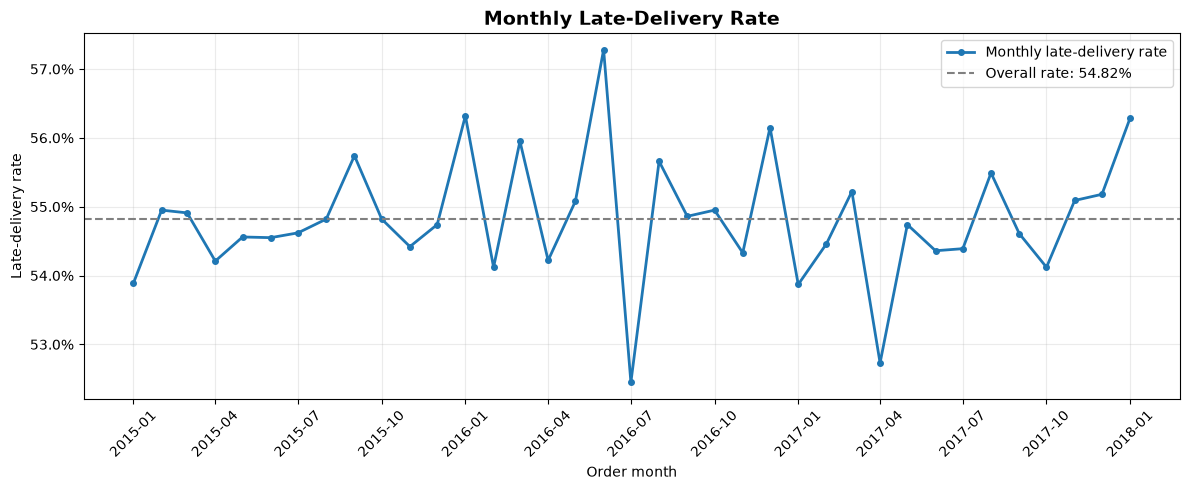

In [28]:
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

monthly_plot = monthly_order_summary.copy()

monthly_plot["month_date"] = (
    monthly_plot["order_month"]
    .dt.to_timestamp()
)

overall_late_rate_pct = (
    order_temporal["Late_delivery_risk"].mean() * 100
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_plot["month_date"],
    monthly_plot["late_rate_pct"],
    marker="o",
    linewidth=2,
    markersize=4,
    label="Monthly late-delivery rate"
)

ax.axhline(
    overall_late_rate_pct,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label=f"Overall rate: {overall_late_rate_pct:.2f}%"
)

ax.set_title(
    "Monthly Late-Delivery Rate",
    fontsize=14,
    weight="bold"
)

ax.set_xlabel("Order month")
ax.set_ylabel("Late-delivery rate")

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=45)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

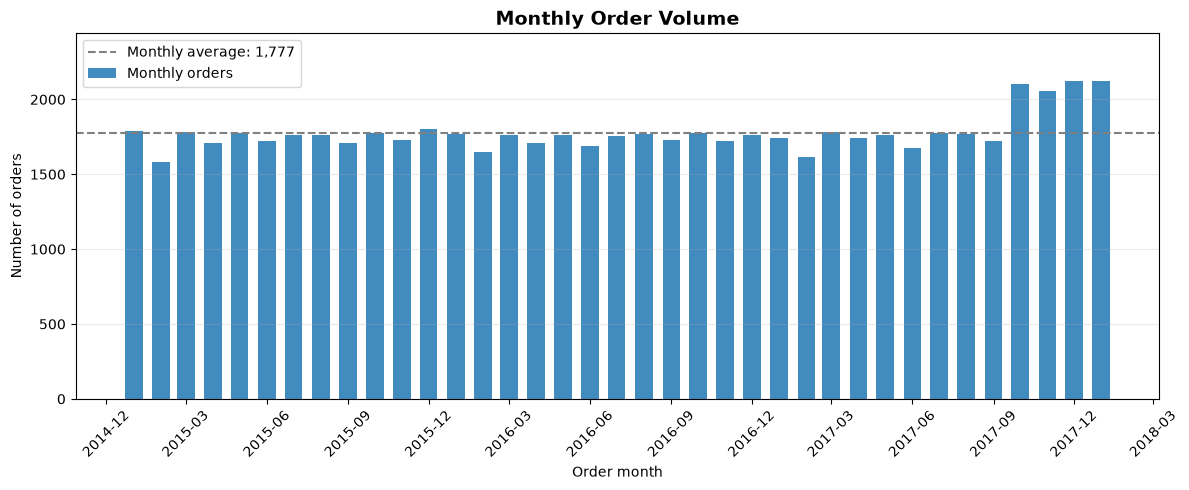

In [29]:
average_monthly_orders = (
    monthly_plot["order_count"].mean()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    monthly_plot["month_date"],
    monthly_plot["order_count"],
    width=20,
    alpha=0.85,
    label="Monthly orders"
)

ax.axhline(
    average_monthly_orders,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label=f"Monthly average: {average_monthly_orders:,.0f}"
)

ax.set_title(
    "Monthly Order Volume",
    fontsize=14,
    weight="bold"
)

ax.set_xlabel("Order month")
ax.set_ylabel("Number of orders")
ax.set_ylim(
    0,
    monthly_plot["order_count"].max() * 1.15
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [30]:
train_end = pd.Timestamp("2017-01-01")
validation_end = pd.Timestamp("2017-07-01")

order_temporal["data_split"] = np.select(
    [
        order_temporal["order_datetime"] < train_end,
        order_temporal["order_datetime"] < validation_end
    ],
    [
        "train",
        "validation"
    ],
    default="test"
)

split_summary = (
    order_temporal
    .groupby("data_split")
    .agg(
        start_date=("order_datetime", "min"),
        end_date=("order_datetime", "max"),
        order_count=("Order Id", "size"),
        late_order_count=("Late_delivery_risk", "sum"),
        late_rate=("Late_delivery_risk", "mean")
    )
    .reindex(["train", "validation", "test"])
    .reset_index()
)

split_summary["share_pct"] = (
    split_summary["order_count"]
    / len(order_temporal)
    * 100
).round(2)

split_summary["late_rate_pct"] = (
    split_summary["late_rate"] * 100
).round(2)

display(
    split_summary[[
        "data_split",
        "start_date",
        "end_date",
        "order_count",
        "share_pct",
        "late_order_count",
        "late_rate_pct"
    ]]
)

print(
    "Total orders across splits:",
    split_summary["order_count"].sum()
)

,data_split,start_date,end_date,order_count,share_pct,late_order_count,late_rate_pct
0,train,2015-01-01 00:00:00,2016-12-31 23:51:00,41763,63.52,22928,54.90
1,validation,2017-01-01 00:33:00,2017-06-30 23:25:00,10319,15.69,5596,54.23
2,test,2017-07-01 00:07:00,2018-01-31 23:38:00,13670,20.79,7524,55.04


Total orders across splits: 65752


## Temporal Validation Strategy

A chronological split was selected at the unique-order level:

- **Train:** January 2015 through December 2016  
  41,763 orders (63.52%), with a 54.90% late-delivery rate.

- **Validation:** January 2017 through June 2017  
  10,319 orders (15.69%), with a 54.23% late-delivery rate.

- **Test:** July 2017 through January 2018  
  13,670 orders (20.79%), with a 55.04% late-delivery rate.

The split preserves chronological order and contains sufficient observations in every period. The test period also includes the increase in monthly order volume observed near the end of the dataset.

A random split will not be used because it would not represent the real requirement of predicting future orders from past data.

The test set is considered locked. Feature selection, model comparison, hyperparameter decisions, calibration and threshold selection will use only train and validation data. Test will be used once for final performance estimation.

In [31]:
excluded_columns = {
    # Confirmed temporal leakage
    "Days for shipping (real)",
    "Delivery Status",
    "Order Status",
    "shipping date (DateOrders)",

    # Empty or constant
    "Product Description",
    "Customer Email",
    "Customer Password",
    "Product Status",

    # Exact duplicates
    "Product Category Id",
    "Order Item Cardprod Id",
    "Product Price",
    "Benefit per order",
    "Sales per customer",

    # Identifiers and personal information
    "Order Item Id",
    "Order Customer Id",
    "Customer Fname",
    "Customer Lname",
    "Customer Street",
    "Customer Zipcode",
    "Latitude",
    "Longitude",
    "Product Image",

    # Excessive missingness
    "Order Zipcode"
}

audit_only_columns = {
    "Order Id",
    "Customer Id"
}

target_columns = {
    "Late_delivery_risk"
}

reviewed_columns = (
    excluded_columns
    | audit_only_columns
    | target_columns
)

remaining_columns = [
    column for column in df_raw.columns
    if column not in reviewed_columns
]

print("Total dataset columns:", len(df_raw.columns))
print("Excluded columns:", len(excluded_columns))
print("Audit-only columns:", len(audit_only_columns))
print("Target columns:", len(target_columns))
print("Remaining candidate columns:", len(remaining_columns))

print("\nRemaining columns:")

for number, column in enumerate(
    remaining_columns,
    start=1
):
    print(f"{number:02d}. {column}")

assert len(reviewed_columns) + len(remaining_columns) == len(df_raw.columns)

Total dataset columns: 53
Excluded columns: 23
Audit-only columns: 2
Target columns: 1
Remaining candidate columns: 27

Remaining columns:
01. Type
02. Days for shipment (scheduled)
03. Category Id
04. Category Name
05. Customer City
06. Customer Country
07. Customer Segment
08. Customer State
09. Department Id
10. Department Name
11. Market
12. Order City
13. Order Country
14. order date (DateOrders)
15. Order Item Discount
16. Order Item Discount Rate
17. Order Item Product Price
18. Order Item Profit Ratio
19. Order Item Quantity
20. Sales
21. Order Item Total
22. Order Profit Per Order
23. Order Region
24. Order State
25. Product Card Id
26. Product Name
27. Shipping Mode


In [32]:
categorical_mapping_pairs = [
    ("Category Id", "Category Name"),
    ("Department Id", "Department Name"),
    ("Product Card Id", "Product Name")
]

mapping_results = []

for id_column, name_column in categorical_mapping_pairs:
    names_per_id = (
        df_raw.groupby(id_column)[name_column]
        .nunique(dropna=False)
    )

    ids_per_name = (
        df_raw.groupby(name_column)[id_column]
        .nunique(dropna=False)
    )

    mapping_results.append({
        "id_column": id_column,
        "name_column": name_column,
        "unique_ids": df_raw[id_column].nunique(),
        "unique_names": df_raw[name_column].nunique(),
        "maximum_names_per_id": names_per_id.max(),
        "maximum_ids_per_name": ids_per_name.max()
    })

categorical_mapping_audit = pd.DataFrame(
    mapping_results
)

display(categorical_mapping_audit)

,id_column,name_column,unique_ids,unique_names,maximum_names_per_id,maximum_ids_per_name
0,Category Id,Category Name,51,50,1,2
1,Department Id,Department Name,11,11,1,1
2,Product Card Id,Product Name,118,118,1,1


In [33]:
category_name_audit = (
    df_raw.groupby("Category Name")
    .agg(
        number_of_ids=("Category Id", "nunique"),
        category_ids=(
            "Category Id",
            lambda values: sorted(values.unique().tolist())
        ),
        row_count=("Category Id", "size")
    )
    .reset_index()
)

duplicated_category_names = (
    category_name_audit.loc[
        category_name_audit["number_of_ids"] > 1
    ]
)

display(duplicated_category_names)

,Category Name,number_of_ids,category_ids,row_count
17,Electronics,2,"[13, 37]",3156


In [34]:
electronics_audit = (
    df_raw.loc[
        df_raw["Category Id"].isin([13, 37])
    ]
    .groupby("Category Id")
    .agg(
        category_name=(
            "Category Name",
            "first"
        ),
        departments=(
            "Department Name",
            lambda values: sorted(values.unique().tolist())
        ),
        number_of_products=(
            "Product Card Id",
            "nunique"
        ),
        product_examples=(
            "Product Name",
            lambda values: sorted(values.unique().tolist())[:5]
        ),
        row_count=(
            "Category Id",
            "size"
        )
    )
    .reset_index()
)

display(electronics_audit)

,Category Id,category_name,departments,number_of_products,product_examples,row_count
0,13,Electronics,[Footwear],4,"[Under Armour Kids' Mercenary Slide, Under Arm...",1127
1,37,Electronics,[Outdoors],7,[Bridgestone e6 Straight Distance NFL Carolina...,2029


## Product Hierarchy Assessment

Department and product identifiers have one-to-one mappings with their descriptive names.

Category identifiers do not have a perfectly one-to-one relationship with category names. The label `Electronics` is shared by:

- Category ID 13 within the `Footwear` department.
- Category ID 37 within the `Outdoors` department.

The two IDs contain different products and should not be merged solely because they share the same label. Product examples also suggest that the `Electronics` label may be inaccurate or overly generic.

Therefore:

- Department and product numeric IDs will not be treated as continuous quantities.
- Product and category IDs may be retained temporarily for distinct counts and traceability.
- Category IDs 13 and 37 will remain distinguishable.
- A composite category label combining department, category and category ID may be created for interpretation.
- Category-name quality will be documented as a limitation of the public dataset.

In [35]:
geography_columns = [
    "Customer City",
    "Customer State",
    "Customer Country",
    "Order City",
    "Order State",
    "Order Country",
    "Order Region",
    "Market"
]

geography_audit = pd.DataFrame({
    "missing_count": (
        df_raw[geography_columns]
        .isna()
        .sum()
    ),
    "unique_values": (
        df_raw[geography_columns]
        .nunique(dropna=True)
    )
})

geography_pairs = [
    ("Customer City", "Order City"),
    ("Customer State", "Order State"),
    ("Customer Country", "Order Country")
]

geography_agreement_results = []

for customer_column, order_column in geography_pairs:
    customer_values = (
        df_raw[customer_column]
        .astype("string")
        .str.strip()
        .str.casefold()
        .fillna("<missing>")
    )

    order_values = (
        df_raw[order_column]
        .astype("string")
        .str.strip()
        .str.casefold()
        .fillna("<missing>")
    )

    geography_agreement_results.append({
        "customer_column": customer_column,
        "order_column": order_column,
        "exact_agreement_pct": round(
            (customer_values == order_values).mean() * 100,
            2
        )
    })

geography_agreement_audit = pd.DataFrame(
    geography_agreement_results
)

print("Geographical cardinality:")
display(
    geography_audit.sort_values(
        "unique_values",
        ascending=False
    )
)

print("Customer versus order geography:")
display(geography_agreement_audit)

Geographical cardinality:


,missing_count,unique_values
Order City,0,3597
Order State,0,1089
Customer City,0,563
Order Country,0,164
Customer State,0,46
Order Region,0,23
Market,0,5
Customer Country,0,2


Customer versus order geography:


,customer_column,order_column,exact_agreement_pct
0,Customer City,Order City,0.07
1,Customer State,Order State,0.00
2,Customer Country,Order Country,0.00


In [36]:
order_geography_columns = [
    "Order City",
    "Order State",
    "Order Country",
    "Order Region",
    "Market"
]

order_geography_consistency = []

for column in order_geography_columns:
    unique_values_per_order = (
        df_raw.groupby("Order Id")[column]
        .nunique(dropna=False)
    )

    order_geography_consistency.append({
        "column": column,
        "orders_with_multiple_values": (
            unique_values_per_order > 1
        ).sum(),
        "maximum_values_within_one_order": (
            unique_values_per_order.max()
        )
    })

order_geography_consistency = pd.DataFrame(
    order_geography_consistency
)

display(order_geography_consistency)

,column,orders_with_multiple_values,maximum_values_within_one_order
0,Order City,0,1
1,Order State,0,1
2,Order Country,0,1
3,Order Region,0,1
4,Market,0,1


In [37]:
order_geography = (
    df_raw[["Order Id"] + order_geography_columns]
    .drop_duplicates(subset="Order Id")
    .merge(
        order_temporal[["Order Id", "data_split"]],
        on="Order Id",
        how="left",
        validate="one_to_one"
    )
)

geography_generalization_results = []

for column in order_geography_columns:
    train_values = set(
        order_geography.loc[
            order_geography["data_split"] == "train",
            column
        ]
    )

    validation_data = order_geography.loc[
        order_geography["data_split"] == "validation",
        column
    ]

    unseen_mask = ~validation_data.isin(train_values)

    geography_generalization_results.append({
        "column": column,
        "unique_in_train": len(train_values),
        "unique_in_validation": validation_data.nunique(),
        "unseen_validation_categories": (
            validation_data.loc[unseen_mask].nunique()
        ),
        "validation_orders_with_unseen_pct": round(
            unseen_mask.mean() * 100,
            2
        )
    })

geography_generalization_audit = pd.DataFrame(
    geography_generalization_results
).sort_values(
    "validation_orders_with_unseen_pct",
    ascending=False
)

display(geography_generalization_audit)

,column,unique_in_train,unique_in_validation,unseen_validation_categories,validation_orders_with_unseen_pct
0,Order City,3511,1151,52,0.74
1,Order State,1071,512,18,0.34
2,Order Country,164,104,0,0.00
3,Order Region,23,17,0,0.00
4,Market,5,5,0,0.00


In [38]:
granular_geography_columns = [
    "Order City",
    "Order State",
    "Order Country"
]

geography_support_results = []

for column in granular_geography_columns:
    train_counts = (
        order_geography.loc[
            order_geography["data_split"] == "train",
            column
        ]
        .value_counts()
    )

    validation_values = order_geography.loc[
        order_geography["data_split"] == "validation",
        column
    ]

    validation_training_support = (
        validation_values
        .map(train_counts)
        .fillna(0)
    )

    geography_support_results.append({
        "column": column,
        "validation_orders_unseen_pct": round(
            (validation_training_support == 0).mean() * 100,
            2
        ),
        "validation_orders_with_train_support_under_5_pct": round(
            (validation_training_support < 5).mean() * 100,
            2
        ),
        "validation_orders_with_train_support_under_20_pct": round(
            (validation_training_support < 20).mean() * 100,
            2
        ),
        "median_train_support_for_validation_orders": int(
            validation_training_support.median()
        )
    })

geography_support_audit = pd.DataFrame(
    geography_support_results
)

display(geography_support_audit)

,column,validation_orders_unseen_pct,validation_orders_with_train_support_under_5_pct,validation_orders_with_train_support_under_20_pct,median_train_support_for_validation_orders
0,Order City,0.74,9.56,34.70,35
1,Order State,0.34,2.70,11.14,101
2,Order Country,0.00,0.09,0.69,619


## Geographical Feature Assessment

Customer geography and order geography represent different concepts and are not redundant. Customer-level city, state and country variables will be excluded from the initial model because they describe customer profile rather than the operational delivery destination.

Order geography is internally consistent within every order.

Generalization analysis using train and validation showed:

- `Market`, `Order Region` and `Order Country` have no unseen validation categories.
- `Order Country` has strong historical support for nearly all validation orders.
- `Order State` has moderate sparsity and will be evaluated as an optional feature.
- `Order City` is highly granular: 34.70% of validation orders belong to cities with fewer than 20 training examples.

Therefore:

- Core geographical predictors: `Market`, `Order Region`, `Order Country`.
- Optional validation experiment: `Order State`.
- Excluded from the initial model: `Order City`.
- City and state may remain available for descriptive analysis and Power BI filtering.
- Categorical preprocessing must safely handle unseen categories.

The test period was not used for this feature decision.

In [39]:
operational_columns = [
    "Type",
    "Customer Segment",
    "Shipping Mode",
    "Days for shipment (scheduled)"
]

operational_audit_results = []

for column in operational_columns:
    values_per_order = (
        df_raw.groupby("Order Id")[column]
        .nunique(dropna=False)
    )

    operational_audit_results.append({
        "column": column,
        "unique_values": df_raw[column].nunique(dropna=True),
        "missing_count": df_raw[column].isna().sum(),
        "orders_with_multiple_values": (
            values_per_order > 1
        ).sum(),
        "maximum_values_within_one_order": (
            values_per_order.max()
        )
    })

operational_audit = pd.DataFrame(
    operational_audit_results
)

display(operational_audit)

for column in operational_columns:
    print(f"\nValues for {column}:")
    print(
        sorted(
            df_raw[column]
            .dropna()
            .unique()
            .tolist()
        )
    )

,column,unique_values,missing_count,orders_with_multiple_values,maximum_values_within_one_order
0,Type,4,0,0,1
1,Customer Segment,3,0,0,1
2,Shipping Mode,4,0,0,1
3,Days for shipment (scheduled),4,0,0,1



Values for Type:
['CASH', 'DEBIT', 'PAYMENT', 'TRANSFER']

Values for Customer Segment:
['Consumer', 'Corporate', 'Home Office']

Values for Shipping Mode:
['First Class', 'Same Day', 'Second Class', 'Standard Class']

Values for Days for shipment (scheduled):
[0, 1, 2, 4]


In [40]:
shipping_schedule_audit = (
    df_raw.groupby("Shipping Mode")
    .agg(
        scheduled_day_values=(
            "Days for shipment (scheduled)",
            lambda values: sorted(values.unique().tolist())
        ),
        unique_scheduled_values=(
            "Days for shipment (scheduled)",
            "nunique"
        ),
        row_count=(
            "Order Id",
            "size"
        )
    )
    .reset_index()
)

scheduled_days_reverse_audit = (
    df_raw.groupby("Days for shipment (scheduled)")
    .agg(
        shipping_modes=(
            "Shipping Mode",
            lambda values: sorted(values.unique().tolist())
        ),
        unique_shipping_modes=(
            "Shipping Mode",
            "nunique"
        )
    )
    .reset_index()
)

print("Scheduled days within each shipping mode:")
display(shipping_schedule_audit)

print("Shipping modes within each scheduled-day value:")
display(scheduled_days_reverse_audit)

Scheduled days within each shipping mode:


,Shipping Mode,scheduled_day_values,unique_scheduled_values,row_count
0,First Class,[1],1,27814
1,Same Day,[0],1,9737
2,Second Class,[2],1,35216
3,Standard Class,[4],1,107752


Shipping modes within each scheduled-day value:


,Days for shipment (scheduled),shipping_modes,unique_shipping_modes
0,0,[Same Day],1
1,1,[First Class],1
2,2,[Second Class],1
3,4,[Standard Class],1


## Shipping-Service Redundancy

`Shipping Mode` and `Days for shipment (scheduled)` have a deterministic one-to-one relationship:

- Same Day = 0 scheduled days.
- First Class = 1 scheduled day.
- Second Class = 2 scheduled days.
- Standard Class = 4 scheduled days.

Both variables are available at order creation and neither represents target leakage. However, including both would represent the same service-level information twice.

`Shipping Mode` will be retained as the primary model predictor because its categories are more interpretable to operational users. Scheduled days may remain available for auditing, reporting and sensitivity analysis, but will not enter the same baseline model simultaneously.

In [41]:
order_operational = (
    df_raw[[
        "Order Id",
        "Type",
        "Customer Segment",
        "Shipping Mode"
    ]]
    .drop_duplicates(subset="Order Id")
    .merge(
        order_temporal[[
            "Order Id",
            "Late_delivery_risk",
            "data_split"
        ]],
        on="Order Id",
        how="left",
        validate="one_to_one"
    )
)

train_operational = order_operational.loc[
    order_operational["data_split"] == "train"
].copy()

train_late_rate_pct = (
    train_operational["Late_delivery_risk"].mean()
    * 100
)

print(
    f"Overall train late-delivery rate: "
    f"{train_late_rate_pct:.2f}%"
)

for column in [
    "Type",
    "Customer Segment",
    "Shipping Mode"
]:
    category_summary = (
        train_operational
        .groupby(column)
        .agg(
            order_count=("Order Id", "size"),
            late_order_count=(
                "Late_delivery_risk",
                "sum"
            ),
            late_rate=(
                "Late_delivery_risk",
                "mean"
            )
        )
        .reset_index()
    )

    category_summary["late_rate_pct"] = (
        category_summary["late_rate"] * 100
    ).round(2)

    category_summary["difference_from_train_pp"] = (
        category_summary["late_rate_pct"]
        - train_late_rate_pct
    ).round(2)

    category_summary = category_summary.sort_values(
        "late_rate_pct",
        ascending=False
    )

    print(f"\nLate-delivery rate by {column}:")
    display(
        category_summary[[
            column,
            "order_count",
            "late_order_count",
            "late_rate_pct",
            "difference_from_train_pp"
        ]]
    )

Overall train late-delivery rate: 54.90%

Late-delivery rate by Type:


,Type,order_count,late_order_count,late_rate_pct,difference_from_train_pp
2,PAYMENT,9592,5526,57.61,2.71
1,DEBIT,16191,9299,57.43,2.53
0,CASH,4602,2607,56.65,1.75
3,TRANSFER,11378,5496,48.30,-6.60



Late-delivery rate by Customer Segment:


,Customer Segment,order_count,late_order_count,late_rate_pct,difference_from_train_pp
1,Corporate,12584,6927,55.05,0.15
0,Consumer,21750,11948,54.93,0.03
2,Home Office,7429,4053,54.56,-0.34



Late-delivery rate by Shipping Mode:


,Shipping Mode,order_count,late_order_count,late_rate_pct,difference_from_train_pp
0,First Class,6422,6135,95.53,40.63
2,Second Class,8116,6237,76.85,21.95
1,Same Day,2248,992,44.13,-10.77
3,Standard Class,24977,9564,38.29,-16.61


In [42]:
stability_results = []

for column in [
    "Type",
    "Customer Segment",
    "Shipping Mode"
]:
    train_summary = (
        order_operational.loc[
            order_operational["data_split"] == "train"
        ]
        .groupby(column)
        .agg(
            train_orders=("Order Id", "size"),
            train_late_rate=(
                "Late_delivery_risk",
                "mean"
            )
        )
    )

    validation_summary = (
        order_operational.loc[
            order_operational["data_split"] == "validation"
        ]
        .groupby(column)
        .agg(
            validation_orders=("Order Id", "size"),
            validation_late_rate=(
                "Late_delivery_risk",
                "mean"
            )
        )
    )

    comparison = (
        train_summary
        .join(validation_summary, how="outer")
        .reset_index()
    )

    comparison["feature"] = column

    comparison["train_late_rate_pct"] = (
        comparison["train_late_rate"] * 100
    ).round(2)

    comparison["validation_late_rate_pct"] = (
        comparison["validation_late_rate"] * 100
    ).round(2)

    comparison["rate_change_pp"] = (
        comparison["validation_late_rate_pct"]
        - comparison["train_late_rate_pct"]
    ).round(2)

    stability_results.append(
        comparison[[
            "feature",
            column,
            "train_orders",
            "validation_orders",
            "train_late_rate_pct",
            "validation_late_rate_pct",
            "rate_change_pp"
        ]].rename(columns={column: "category"})
    )

operational_stability = pd.concat(
    stability_results,
    ignore_index=True
)

display(operational_stability)

,feature,category,train_orders,validation_orders,train_late_rate_pct,validation_late_rate_pct,rate_change_pp
0,Type,CASH,4602,1138,56.65,57.82,1.17
1,Type,DEBIT,16191,3918,57.43,55.59,-1.84
2,Type,PAYMENT,9592,2348,57.61,57.24,-0.37
3,Type,TRANSFER,11378,2915,48.30,48.58,0.28
4,Customer Segment,Consumer,21750,5281,54.93,53.82,-1.11
5,Customer Segment,Corporate,12584,3158,55.05,53.48,-1.57
6,Customer Segment,Home Office,7429,1880,54.56,56.65,2.09
7,Shipping Mode,First Class,6422,1576,95.53,94.73,-0.80
8,Shipping Mode,Same Day,2248,552,44.13,47.46,3.33
9,Shipping Mode,Second Class,8116,1962,76.85,75.59,-1.26


## Operational Feature Stability

Train and validation show consistent patterns for payment type and shipping mode.

`TRANSFER` orders have a substantially lower late-delivery rate than the other payment types in both periods.

`Shipping Mode` is the strongest operational predictor identified:

- First Class has the highest late-delivery rate.
- Second Class has the second-highest rate.
- Same Day and Standard Class have substantially lower rates.
- The ranking remains stable from train to validation.

This association should not be interpreted causally. Shipping mode determines the delivery promise, so changing to a slower service may reduce the late-delivery label without reducing physical transit time.

`Customer Segment` shows limited and less stable univariate separation. It will remain an initial candidate because it is available, low-cardinality and operationally plausible, but its incremental contribution will be evaluated using validation and model interpretation.

## Planned Order-Level Feature Mart

The modeling dataset will contain one row per `Order Id`.

### Traceability fields

Retained for joins, splitting and reporting, but not used directly as predictors:

- `Order Id`
- `Customer Id`
- Order timestamp
- Data split

### Order-level categorical candidates

- Payment type
- Customer segment
- Shipping mode
- Market
- Order region
- Order country
- Order state as an optional validation experiment

### Calendar features available at order creation

- Order month
- Order quarter
- Order day of week
- Order hour
- Weekend indicator

### Product-composition features

- Number of order-item rows
- Total quantity
- Number of distinct products
- Number of distinct categories
- Number of distinct departments
- Primary department by gross sales
- Primary category by gross sales

### Monetary features

- Gross sales
- Total discount
- Net sales
- Total profit
- Weighted average unit price
- Recalculated order discount rate
- Recalculated order profit margin

### Target

- `Late_delivery_risk`

All aggregations use information available at order creation. Stored rounded rates will not be averaged. Identifiers, personal information, post-order outcomes and confirmed leakage variables will not enter the model.

In [43]:
order_base = (
    df_raw.assign(order_datetime=order_datetime)[[
        "Order Id",
        "Customer Id",
        "order_datetime",
        "Late_delivery_risk",
        "Type",
        "Customer Segment",
        "Shipping Mode",
        "Market",
        "Order Region",
        "Order Country",
        "Order State",
        "Order City"
    ]]
    .drop_duplicates(subset="Order Id")
    .rename(columns={
        "Order Id": "order_id",
        "Customer Id": "customer_id",
        "Late_delivery_risk": "late_delivery_risk",
        "Type": "payment_type",
        "Customer Segment": "customer_segment",
        "Shipping Mode": "shipping_mode",
        "Market": "market",
        "Order Region": "order_region",
        "Order Country": "order_country",
        "Order State": "order_state",
        "Order City": "order_city"
    })
    .merge(
        order_temporal[[
            "Order Id",
            "data_split"
        ]].rename(columns={
            "Order Id": "order_id"
        }),
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .sort_values("order_datetime")
    .reset_index(drop=True)
)

order_base["order_month"] = (
    order_base["order_datetime"].dt.month
)

order_base["order_quarter"] = (
    order_base["order_datetime"].dt.quarter
)

order_base["order_day_of_week"] = (
    order_base["order_datetime"].dt.dayofweek
)

order_base["order_hour"] = (
    order_base["order_datetime"].dt.hour
)

order_base["is_weekend"] = (
    order_base["order_day_of_week"] >= 5
).astype(int)

print("Order-level rows:", len(order_base))
print(
    "Unique order IDs:",
    order_base["order_id"].nunique()
)
print(
    "Duplicate order IDs:",
    order_base["order_id"].duplicated().sum()
)
print(
    "Missing split assignments:",
    order_base["data_split"].isna().sum()
)
print(
    "Missing values in order base:",
    order_base.isna().sum().sum()
)

display(order_base.head())

Order-level rows: 65752
Unique order IDs: 65752
Duplicate order IDs: 0
Missing split assignments: 0
Missing values in order base: 0


,order_id,customer_id,order_datetime,late_delivery_risk,payment_type,customer_segment,shipping_mode,market,order_region,order_country,order_state,order_city,data_split,order_month,order_quarter,order_day_of_week,order_hour,is_weekend
0,1,11599,2015-01-01 00:00:00,0,CASH,Consumer,Standard Class,LATAM,Central America,México,Distrito Federal,Mexico City,train,1,1,3,0,0
1,2,256,2015-01-01 00:21:00,0,PAYMENT,Consumer,Standard Class,LATAM,South America,Colombia,Risaralda,Dos Quebradas,train,1,1,3,0,0
2,4,8827,2015-01-01 01:03:00,1,CASH,Home Office,Standard Class,LATAM,South America,Colombia,Risaralda,Dos Quebradas,train,1,1,3,1,0
3,5,11318,2015-01-01 01:24:00,1,DEBIT,Consumer,Standard Class,LATAM,South America,Colombia,Risaralda,Dos Quebradas,train,1,1,3,1,0
4,7,4530,2015-01-01 02:06:00,1,DEBIT,Consumer,Second Class,LATAM,South America,Brasil,São Paulo,São Paulo,train,1,1,3,2,0


In [44]:
order_item_features = (
    df_raw.groupby("Order Id")
    .agg(
        order_line_count=(
            "Order Item Id",
            "size"
        ),
        total_item_quantity=(
            "Order Item Quantity",
            "sum"
        ),
        distinct_products=(
            "Product Card Id",
            "nunique"
        ),
        distinct_categories=(
            "Category Id",
            "nunique"
        ),
        distinct_departments=(
            "Department Id",
            "nunique"
        ),
        gross_sales=(
            "Sales",
            "sum"
        ),
        total_discount=(
            "Order Item Discount",
            "sum"
        ),
        net_sales=(
            "Order Item Total",
            "sum"
        ),
        total_profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
    .rename(columns={
        "Order Id": "order_id"
    })
)

order_item_features["weighted_avg_unit_price"] = (
    order_item_features["gross_sales"]
    / order_item_features["total_item_quantity"]
)

order_item_features["order_discount_rate"] = (
    order_item_features["total_discount"]
    / order_item_features["gross_sales"]
)

order_item_features["order_profit_margin"] = (
    order_item_features["total_profit"]
    / order_item_features["net_sales"]
)

print(
    "Aggregated order rows:",
    len(order_item_features)
)
print(
    "Unique order IDs:",
    order_item_features["order_id"].nunique()
)
print(
    "Duplicate order IDs:",
    order_item_features["order_id"].duplicated().sum()
)
print(
    "Missing values:",
    order_item_features.isna().sum().sum()
)

display(
    order_item_features.drop(
        columns="order_id"
    ).describe().T.round(2)
)

Aggregated order rows: 65752
Unique order IDs: 65752
Duplicate order IDs: 0
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
order_line_count,65752.0,2.75,1.48,1.00,1.00,3.00,4.00,5.00
total_item_quantity,65752.0,5.84,4.17,1.00,2.00,5.00,9.00,24.00
distinct_products,65752.0,2.43,1.26,1.00,1.00,2.00,3.00,5.00
distinct_categories,65752.0,2.43,1.25,1.00,1.00,2.00,3.00,5.00
distinct_departments,65752.0,2.00,0.94,1.00,1.00,2.00,3.00,5.00
gross_sales,65752.0,559.45,355.54,9.99,265.96,504.89,799.95,3449.91
total_discount,65752.0,56.73,46.58,0.00,20.00,47.39,82.39,681.50
net_sales,65752.0,502.71,320.95,7.49,244.78,455.95,721.19,2768.41
total_profit,65752.0,60.33,189.72,-4325.85,7.80,72.73,158.67,980.28
weighted_avg_unit_price,65752.0,134.70,149.49,9.99,59.99,91.99,149.98,1500.00


In [45]:
net_sales_residual = (
    order_item_features["net_sales"]
    - (
        order_item_features["gross_sales"]
        - order_item_features["total_discount"]
    )
).abs()

negative_profit_mask = (
    order_item_features["total_profit"] < 0
)

extreme_negative_margin_mask = (
    order_item_features["order_profit_margin"] < -1
)

print(
    "Maximum net-sales arithmetic difference:",
    net_sales_residual.max()
)

print(
    "Orders with non-positive gross sales:",
    (order_item_features["gross_sales"] <= 0).sum()
)

print(
    "Orders with non-positive net sales:",
    (order_item_features["net_sales"] <= 0).sum()
)

print(
    "Orders with negative profit:",
    negative_profit_mask.sum()
)

print(
    "Negative-profit percentage:",
    f"{negative_profit_mask.mean() * 100:.2f}%"
)

print(
    "Orders with profit margin below -100%:",
    extreme_negative_margin_mask.sum()
)

print("\nTen orders with the lowest profit margins:")

display(
    order_item_features.nsmallest(
        10,
        "order_profit_margin"
    )[[
        "order_id",
        "gross_sales",
        "total_discount",
        "net_sales",
        "total_profit",
        "order_profit_margin"
    ]]
)

Maximum net-sales arithmetic difference: 0.02001387999985127
Orders with non-positive gross sales: 0
Orders with non-positive net sales: 0
Orders with negative profit: 13909
Negative-profit percentage: 21.15%
Orders with profit margin below -100%: 1335

Ten orders with the lowest profit margins:


,order_id,gross_sales,total_discount,net_sales,total_profit,order_profit_margin
64698,76151,11.540000,2.31,9.230000,-25.389999,-2.750813
3443,4125,49.980000,6.00,43.980000,-120.949997,-2.750114
36010,43185,299.980011,30.00,269.980011,-742.450012,-2.750018
57138,68522,329.989990,16.50,313.489990,-862.099976,-2.750008
49295,59078,319.959992,6.40,313.559998,-862.289978,-2.750000
58284,69737,452.040008,13.56,438.480011,-1205.819946,-2.750000
61432,72885,84.400002,10.97,73.430000,-201.929993,-2.749966
62051,73504,39.750000,3.58,36.169998,-97.669998,-2.700304
27418,32815,31.990000,5.44,26.549999,-71.690002,-2.700188
38986,46743,49.980000,7.50,42.480000,-114.699997,-2.700094


## Order-Level Numerical Feature Audit

The order-item aggregation produced 65,752 unique orders with no missing values or duplicate order identifiers.

Net sales are arithmetically consistent with gross sales minus discount. The maximum residual is 0.02 monetary units and is attributable to accumulated line-level currency rounding.

All are strictly positive:

- Gross sales.
- Net sales.
- Total item quantity.

Profitability has a substantial negative tail:

- 13,909 orders (21.15%) have negative total profit.
- 1,335 orders have profit margins below -100%.
- The lowest margins concentrate near -275%.

These observations will not be automatically removed, clipped or winsorized because they represent a material portion of the dataset and are internally consistent.

The exact availability of profit information at order creation is not fully documented. Therefore, sensitivity analysis will compare:

1. An operational model excluding profit and profit margin.
2. An extended model including profitability variables under the assumption that standard cost is available at order creation.

This prevents the final solution from depending silently on a feature with uncertain production availability.

In [46]:
order_category_sales = (
    df_raw.groupby([
        "Order Id",
        "Department Name",
        "Category Name",
        "Category Id"
    ])
    .agg(
        category_gross_sales=(
            "Sales",
            "sum"
        )
    )
    .reset_index()
)

primary_category = (
    order_category_sales
    .sort_values(
        by=[
            "Order Id",
            "category_gross_sales",
            "Category Id"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .drop_duplicates(
        subset="Order Id",
        keep="first"
    )
    .rename(columns={
        "Order Id": "order_id",
        "Department Name": "primary_department",
        "Category Name": "primary_category_name",
        "Category Id": "primary_category_id",
        "category_gross_sales": "primary_category_sales"
    })
)

primary_category["primary_category_label"] = (
    primary_category["primary_department"]
    + " | "
    + primary_category["primary_category_name"]
    + " | ID "
    + primary_category["primary_category_id"].astype(str)
)

primary_category = primary_category.merge(
    order_item_features[[
        "order_id",
        "gross_sales"
    ]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

primary_category["primary_category_sales_share"] = (
    primary_category["primary_category_sales"]
    / primary_category["gross_sales"]
)

print(
    "Orders with primary category:",
    len(primary_category)
)
print(
    "Unique order IDs:",
    primary_category["order_id"].nunique()
)
print(
    "Missing values:",
    primary_category.isna().sum().sum()
)
print(
    "Minimum primary-category sales share:",
    primary_category[
        "primary_category_sales_share"
    ].min()
)
print(
    "Maximum primary-category sales share:",
    primary_category[
        "primary_category_sales_share"
    ].max()
)

display(
    primary_category[[
        "order_id",
        "primary_department",
        "primary_category_label",
        "primary_category_sales",
        "primary_category_sales_share"
    ]].head()
)

Orders with primary category: 65752
Unique order IDs: 65752
Missing values: 0
Minimum primary-category sales share: 0.21979712534327114
Maximum primary-category sales share: 1.0


,order_id,primary_department,primary_category_label,primary_category_sales,primary_category_sales_share
0,1,Fan Shop,Fan Shop | Camping & Hiking | ID 43,299.980011,1.000000
1,2,Golf,Golf | Women's Apparel | ID 24,250.000000,0.431049
2,4,Apparel,Apparel | Cleats | ID 17,299.950012,0.428592
3,5,Fan Shop,Fan Shop | Camping & Hiking | ID 43,599.960022,0.531004
4,7,Fan Shop,Fan Shop | Camping & Hiking | ID 43,299.980011,0.517278


In [47]:
primary_category_with_split = (
    primary_category
    .merge(
        order_temporal[[
            "Order Id",
            "data_split"
        ]].rename(columns={
            "Order Id": "order_id"
        }),
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

category_support_results = []

for column in [
    "primary_department",
    "primary_category_label"
]:
    train_counts = (
        primary_category_with_split.loc[
            primary_category_with_split[
                "data_split"
            ] == "train",
            column
        ]
        .value_counts()
    )

    validation_values = (
        primary_category_with_split.loc[
            primary_category_with_split[
                "data_split"
            ] == "validation",
            column
        ]
    )

    validation_support = (
        validation_values
        .map(train_counts)
        .fillna(0)
    )

    category_support_results.append({
        "column": column,
        "unique_in_train": len(train_counts),
        "unique_in_validation": (
            validation_values.nunique()
        ),
        "unseen_validation_categories": (
            validation_values.loc[
                validation_support == 0
            ].nunique()
        ),
        "validation_orders_unseen_pct": round(
            (validation_support == 0).mean() * 100,
            2
        ),
        "validation_orders_with_train_support_under_20_pct": round(
            (validation_support < 20).mean() * 100,
            2
        ),
        "median_train_support_for_validation_orders": int(
            validation_support.median()
        )
    })

category_support_audit = pd.DataFrame(
    category_support_results
)

display(category_support_audit)

,column,unique_in_train,unique_in_validation,unseen_validation_categories,validation_orders_unseen_pct,validation_orders_with_train_support_under_20_pct,median_train_support_for_validation_orders
0,primary_department,6,6,0,0.00,0.00,22488
1,primary_category_label,25,32,7,1.39,1.57,4391


In [48]:
feature_mart = (
    order_base
    .merge(
        order_item_features,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        primary_category[[
            "order_id",
            "primary_department",
            "primary_category_label",
            "primary_category_sales_share"
        ]],
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .sort_values("order_datetime")
    .reset_index(drop=True)
)

print("Feature-mart rows:", len(feature_mart))
print("Feature-mart columns:", feature_mart.shape[1])
print(
    "Unique order IDs:",
    feature_mart["order_id"].nunique()
)
print(
    "Duplicate order IDs:",
    feature_mart["order_id"].duplicated().sum()
)
print(
    "Missing values:",
    feature_mart.isna().sum().sum()
)
print(
    "Chronologically sorted:",
    feature_mart["order_datetime"].is_monotonic_increasing
)

print("\nRows by split:")
display(
    feature_mart["data_split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .rename_axis("data_split")
    .reset_index(name="order_count")
)

display(feature_mart.head())

Feature-mart rows: 65752
Feature-mart columns: 33
Unique order IDs: 65752
Duplicate order IDs: 0
Missing values: 0
Chronologically sorted: True

Rows by split:


,data_split,order_count
0,train,41763
1,validation,10319
2,test,13670


,order_id,customer_id,order_datetime,late_delivery_risk,payment_type,customer_segment,shipping_mode,market,order_region,order_country,...,gross_sales,total_discount,net_sales,total_profit,weighted_avg_unit_price,order_discount_rate,order_profit_margin,primary_department,primary_category_label,primary_category_sales_share
0,1,11599,2015-01-01 00:00:00,0,CASH,Consumer,Standard Class,LATAM,Central America,México,...,299.980011,60.000000,239.979996,88.790001,299.980011,0.200013,0.369989,Fan Shop,Fan Shop | Camping & Hiking | ID 43,1.000000
1,2,256,2015-01-01 00:21:00,0,PAYMENT,Consumer,Standard Class,LATAM,South America,Colombia,...,579.980011,50.600000,529.380005,195.900002,82.854287,0.087244,0.370056,Golf,Golf | Women's Apparel | ID 24,0.431049
2,4,8827,2015-01-01 01:03:00,1,CASH,Home Office,Standard Class,LATAM,South America,Colombia,...,699.850010,78.980000,620.870014,124.090000,49.989286,0.112853,0.199865,Apparel,Apparel | Cleats | ID 17,0.428592
3,5,11318,2015-01-01 01:24:00,1,DEBIT,Consumer,Standard Class,LATAM,South America,Colombia,...,1129.860039,142.789999,987.070007,390.089995,112.986004,0.126378,0.395200,Fan Shop,Fan Shop | Camping & Hiking | ID 43,0.531004
4,7,4530,2015-01-01 02:06:00,1,DEBIT,Consumer,Second Class,LATAM,South America,Brasil,...,579.920013,54.400000,525.520004,203.929998,82.845716,0.093806,0.388054,Fan Shop,Fan Shop | Camping & Hiking | ID 43,0.517278


In [49]:
OUTPUT_DIR = PROJECT_ROOT / "outputs"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FEATURE_MART_PATH = (
    OUTPUT_DIR
    / "feature_mart_order_level.csv"
)

feature_mart.to_csv(
    FEATURE_MART_PATH,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)

file_size_mb = (
    FEATURE_MART_PATH.stat().st_size
    / (1024 ** 2)
)

print(
    "Saved file:",
    FEATURE_MART_PATH
)

print(
    "File exists:",
    FEATURE_MART_PATH.exists()
)

print(
    f"File size: {file_size_mb:.2f} MB"
)

print(
    "Exported rows:",
    len(feature_mart)
)

print(
    "Exported columns:",
    feature_mart.shape[1]
)

Saved file: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery\outputs\feature_mart_order_level.csv
File exists: True
File size: 18.99 MB
Exported rows: 65752
Exported columns: 33


In [50]:
feature_mart_check = pd.read_csv(
    FEATURE_MART_PATH,
    encoding="utf-8-sig",
    parse_dates=["order_datetime"]
)

print(
    "Reloaded shape:",
    feature_mart_check.shape
)

print(
    "Unique order IDs:",
    feature_mart_check["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    feature_mart_check["order_id"].duplicated().sum()
)

print(
    "Missing values:",
    feature_mart_check.isna().sum().sum()
)

print(
    "Order datetime dtype:",
    feature_mart_check["order_datetime"].dtype
)

try:
    pd.testing.assert_frame_equal(
        feature_mart.reset_index(drop=True),
        feature_mart_check.reset_index(drop=True),
        check_dtype=False,
        check_exact=False,
        rtol=1e-10,
        atol=1e-10
    )

    round_trip_validated = True

except AssertionError as error:
    round_trip_validated = False
    print("Comparison difference:", error)

print(
    "Round-trip validation passed:",
    round_trip_validated
)

Reloaded shape: (65752, 33)
Unique order IDs: 65752
Duplicate order IDs: 0
Missing values: 0
Order datetime dtype: datetime64[us]
Round-trip validation passed: True


In [51]:
import duckdb

SQL_DIR = PROJECT_ROOT / "sql"

SQL_FEATURE_MART_PATH = (
    SQL_DIR
    / "01_build_order_feature_mart.sql"
)

sql_query = SQL_FEATURE_MART_PATH.read_text(
    encoding="utf-8"
)

duckdb_connection = duckdb.connect()

duckdb_connection.register(
    "raw_orders",
    df_raw
)

sql_order_features = (
    duckdb_connection
    .execute(sql_query)
    .df()
)

print(
    "DuckDB version:",
    duckdb.__version__
)

print(
    "SQL file exists:",
    SQL_FEATURE_MART_PATH.exists()
)

print(
    "SQL result shape:",
    sql_order_features.shape
)

print(
    "Unique order IDs:",
    sql_order_features["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    sql_order_features["order_id"].duplicated().sum()
)

display(sql_order_features.head())

DuckDB version: 1.5.5
SQL file exists: True
SQL result shape: (65752, 13)
Unique order IDs: 65752
Duplicate order IDs: 0


,order_id,order_line_count,total_item_quantity,distinct_products,distinct_categories,distinct_departments,gross_sales,total_discount,net_sales,total_profit,weighted_avg_unit_price,order_discount_rate,order_profit_margin
0,1,1,1.0,1,1,1,299.980011,60.000000,239.979996,88.790001,299.980011,0.200013,0.369989
1,2,3,7.0,3,3,3,579.980011,50.600000,529.380005,195.900002,82.854287,0.087244,0.370056
2,4,4,14.0,4,4,4,699.850010,78.980000,620.870014,124.090000,49.989286,0.112853,0.199865
3,5,5,10.0,4,4,2,1129.860039,142.789999,987.070007,390.089995,112.986004,0.126378,0.395200
4,7,3,7.0,3,3,2,579.920013,54.400000,525.520004,203.929998,82.845716,0.093806,0.388054


In [52]:
sql_comparison_columns = [
    "order_id",
    "order_line_count",
    "total_item_quantity",
    "distinct_products",
    "distinct_categories",
    "distinct_departments",
    "gross_sales",
    "total_discount",
    "net_sales",
    "total_profit"
]

pandas_aggregation_check = (
    order_item_features[
        sql_comparison_columns
    ]
    .sort_values("order_id")
    .reset_index(drop=True)
)

sql_aggregation_check = (
    sql_order_features[
        sql_comparison_columns
    ]
    .sort_values("order_id")
    .reset_index(drop=True)
)

try:
    pd.testing.assert_frame_equal(
        pandas_aggregation_check,
        sql_aggregation_check,
        check_dtype=False,
        check_exact=False,
        rtol=1e-9,
        atol=1e-8
    )

    sql_matches_pandas = True

except AssertionError as error:
    sql_matches_pandas = False
    print("Comparison difference:", error)

print(
    "SQL aggregation matches pandas:",
    sql_matches_pandas
)

SQL aggregation matches pandas: True


In [53]:
sql_query = SQL_FEATURE_MART_PATH.read_text(
    encoding="utf-8"
)

sql_order_features = (
    duckdb_connection
    .execute(sql_query)
    .df()
)

full_sql_columns = (
    order_item_features.columns.tolist()
)

pandas_full_check = (
    order_item_features[full_sql_columns]
    .sort_values("order_id")
    .reset_index(drop=True)
)

sql_full_check = (
    sql_order_features[full_sql_columns]
    .sort_values("order_id")
    .reset_index(drop=True)
)

try:
    pd.testing.assert_frame_equal(
        pandas_full_check,
        sql_full_check,
        check_dtype=False,
        check_exact=False,
        rtol=1e-9,
        atol=1e-8
    )

    full_sql_matches_pandas = True

except AssertionError as error:
    full_sql_matches_pandas = False
    print("Comparison difference:", error)

print(
    "Updated SQL result shape:",
    sql_order_features.shape
)

print(
    "Full SQL aggregation matches pandas:",
    full_sql_matches_pandas
)

display(sql_order_features.head())

Updated SQL result shape: (65752, 13)
Full SQL aggregation matches pandas: True


,order_id,order_line_count,total_item_quantity,distinct_products,distinct_categories,distinct_departments,gross_sales,total_discount,net_sales,total_profit,weighted_avg_unit_price,order_discount_rate,order_profit_margin
0,1,1,1.0,1,1,1,299.980011,60.000000,239.979996,88.790001,299.980011,0.200013,0.369989
1,2,3,7.0,3,3,3,579.980011,50.600000,529.380005,195.900002,82.854287,0.087244,0.370056
2,4,4,14.0,4,4,4,699.850010,78.980000,620.870014,124.090000,49.989286,0.112853,0.199865
3,5,5,10.0,4,4,2,1129.860039,142.789999,987.070007,390.089995,112.986004,0.126378,0.395200
4,7,3,7.0,3,3,2,579.920013,54.400000,525.520004,203.929998,82.845716,0.093806,0.388054
